# Lecture 7 — Class Exercise
## Part-to-Whole: Hierarchical Visualization

> **Push to:** `week07/lecture07_exercise.ipynb`


In [3]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Global Energy Mix by Country and Source
df = pd.read_csv('../data/global_energy_mix.csv')

# Source type mapping — reuse from lecture
source_category = {
    'Coal': 'Fossil', 'Oil': 'Fossil', 'Natural Gas': 'Fossil',
    'Nuclear': 'Low-carbon', 'Hydro': 'Low-carbon',
    'Wind': 'Renewable', 'Solar': 'Renewable', 'Other Renewables': 'Renewable'
}
df['Source_Type'] = df['Source'].map(source_category)

print(f"Loaded: {len(df)} rows")
print(df.head(10))


Loaded: 103 rows
         Country         Region            Source  Share_pct     TWh  \
0  United States  North America              Coal         10  1015.0   
1  United States  North America               Oil         35  3220.0   
2  United States  North America       Natural Gas         34  3083.0   
3  United States  North America           Nuclear          9   798.0   
4  United States  North America             Hydro          3   339.0   
5  United States  North America              Wind          4   413.0   
6  United States  North America             Solar          3   325.0   
7  United States  North America  Other Renewables          2   229.0   
8          China           Asia              Coal         58  6929.1   
9          China           Asia               Oil         18  1620.0   

  Source_Type  
0      Fossil  
1      Fossil  
2      Fossil  
3  Low-carbon  
4  Low-carbon  
5   Renewable  
6   Renewable  
7   Renewable  
8      Fossil  
9      Fossil  


## Task 1 — Treemap: fossil fuel dependency by country

**What to build:** A treemap showing **fossil fuel TWh only**, broken down by Region → Country → Source (Coal / Oil / Natural Gas).

**Requirements:**
- Filter to fossil sources only before plotting
- Use `path=['Region', 'Country', 'Source']` for the hierarchy
- Colour encodes the fossil source type (Coal / Oil / Natural Gas) with a CVD-safe palette
- Show TWh values in labels — no percentages
- Grey out parent nodes (Region and Country level)
- Insight title naming which region or country is most fossil-dependent

> 💡 `df.loc[df['Source_Type'] == 'Fossil']`


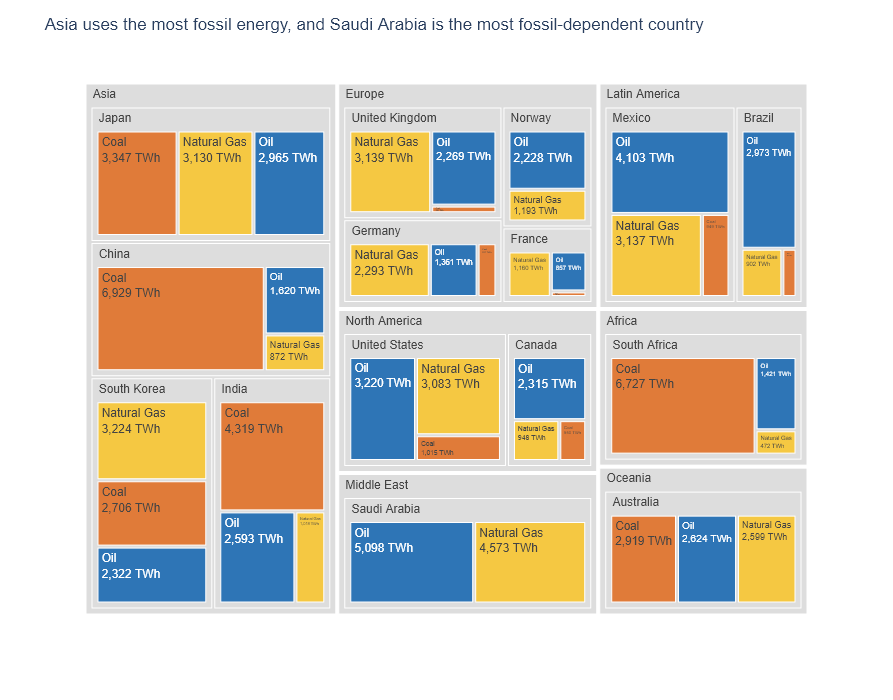

In [4]:
# Task 1
# YOUR CODE HERE

df_fossil = df.loc[df['Source_Type'] == 'Fossil']

# Find the region and country with the most fossil TWh (for the title)
top_region = df_fossil.groupby('Region')['TWh'].sum().idxmax()
top_country = df_fossil.groupby('Country')['TWh'].sum().idxmax()

# CVD-safe colours (course palette)
fossil_colors = {
    'Coal':        '#E07B39',   # orange
    'Oil':         '#2E75B6',   # blue
    'Natural Gas': '#F5C842',   # yellow
}

fig = px.treemap(
    df_fossil,
    path=['Region', 'Country', 'Source'],
    values='TWh',
    color='Source',
    color_discrete_map=fossil_colors,
    height=700, width=1100,
    template='plotly_white'
)

# Show TWh only, no percentages
fig.update_traces(
    texttemplate='%{label}<br>%{value:,.0f} TWh',
    hovertemplate='<b>%{label}</b><br>%{value:,.0f} TWh'
)

# Grey out parent nodes (Region and Country)
fig.data[0].marker.colors = [
    c if c in fossil_colors.values() else '#DDDDDD'
    for c in fig.data[0].marker.colors
]

fig.update_layout(
    title=f'{top_region} uses the most fossil energy, and {top_country} is the most fossil-dependent country',
    font=dict(family='Arial', size=12)
)

fig.show()


## Task 2 — Treemap vs bar: low-carbon energy by country

**What to build:** Build **both** a treemap and a horizontal bar chart showing total low-carbon TWh (Nuclear + Hydro) per country. Then answer the question in a markdown cell below.

**Requirements:**
- Filter to `Source_Type == 'Low-carbon'` and aggregate TWh by country
- Treemap: single-level `path=['All', 'Country']` with a dummy root node labelled `'Low-carbon'`
- Bar chart: sorted by TWh, horizontal orientation, CVD-safe colour
- Both charts show TWh values, not percentages
- Insight title on the bar chart naming the leading country

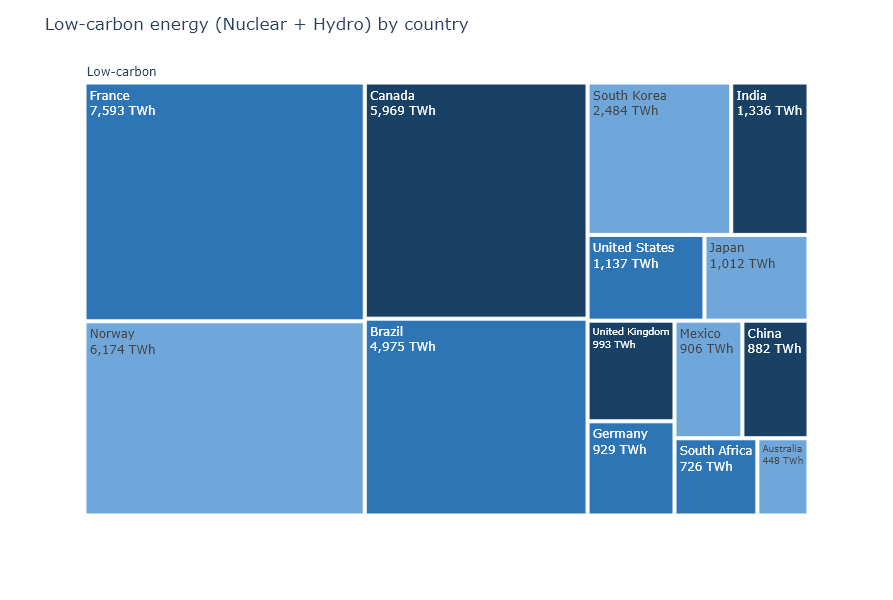

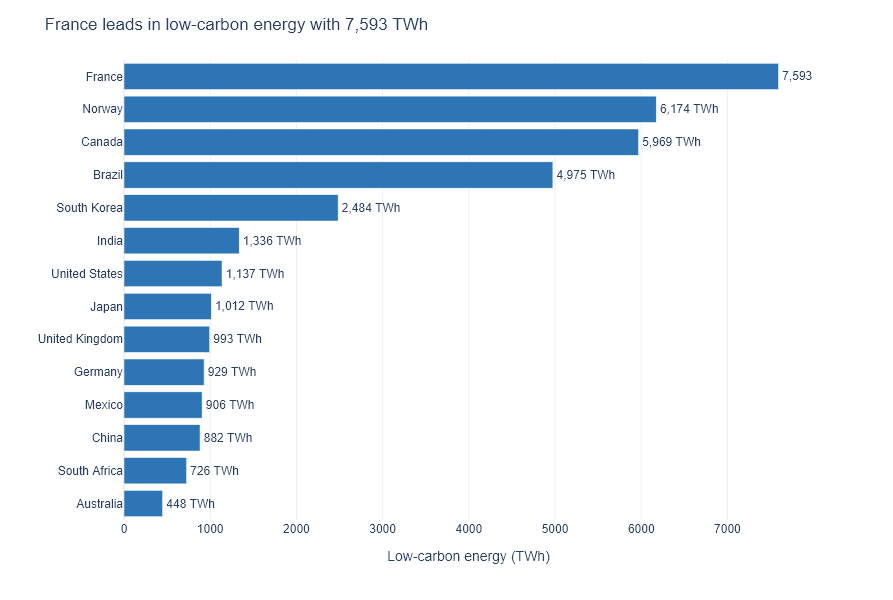

In [5]:
# Task 2 — charts
# YOUR CODE HERE

# Keep only low-carbon sources and add up TWh per country
df_low = df.loc[df['Source_Type'] == 'Low-carbon']
low_by_country = df_low.groupby('Country')['TWh'].sum().reset_index()

# Dummy root node for the treemap
low_by_country['All'] = 'Low-carbon'

# ---- Treemap ----
fig1 = px.treemap(
    low_by_country,
    path=['All', 'Country'],
    values='TWh',
    color_discrete_sequence=['#2E75B6'],
    height=600, width=1000,
    template='plotly_white'
)

fig1.update_traces(
    texttemplate='%{label}<br>%{value:,.0f} TWh',
    hovertemplate='<b>%{label}</b><br>%{value:,.0f} TWh'
)

fig1.update_layout(title='Low-carbon energy (Nuclear + Hydro) by country')
fig1.show()

# ---- Horizontal bar chart ----
low_sorted = low_by_country.sort_values('TWh')   # smallest at bottom, largest at top
leader = low_sorted.iloc[-1]                     # last row = biggest

fig2 = px.bar(
    low_sorted,
    x='TWh', y='Country',
    orientation='h',
    text='TWh',
    color_discrete_sequence=['#2E75B6'],
    height=600, width=1000,
    template='plotly_white'
)

fig2.update_traces(texttemplate='%{text:,.0f} TWh', textposition='outside')

fig2.update_layout(
    title=f"{leader['Country']} leads in low-carbon energy with {leader['TWh']:,.0f} TWh",
    xaxis_title='Low-carbon energy (TWh)',
    yaxis_title='',
    font=dict(family='Arial', size=12)
)

fig2.show()

### Task 2 — reflection

**Which chart tells the ranking story more clearly, and why?**

*YOUR ANSWER HERE*

The bar chart tells the ranking story more clearly. All the bars start from the same baseline and are sorted, so you can read the order from top to bottom and compare lengths exactly. In the treemap you have to compare the areas of rectangles that sit in different places, which is much harder. You can see the biggest countries, but it’s hard to tell how the similar-sized ones rank.

## Task 3 — 100% stacked bar: which region relies most on coal?

**What to build:** A horizontal 100% stacked bar chart showing, for each **Region**, how its fossil energy splits between Coal, Oil and Natural Gas. This is the **same data as your Task 1 treemap**, visualised a second way.

**Requirements:**
- Reuse `df_fossil` from Task 1; aggregate TWh by `Region` × `Source` and convert to **shares of each region's fossil total**
- Horizontal bars, regions **sorted by coal share** (highest at the top)
- Coal is the segment on the baseline (first in `category_orders`) and the **only coloured segment** — keep it the same colour as in Task 1; Oil and Natural Gas in two greys
- Percentage labels on the coal segments only
- Insight title naming the most coal-dependent region and its coal share

> 💡 `df.groupby('Region')['TWh'].transform('sum')` gives each row its region total

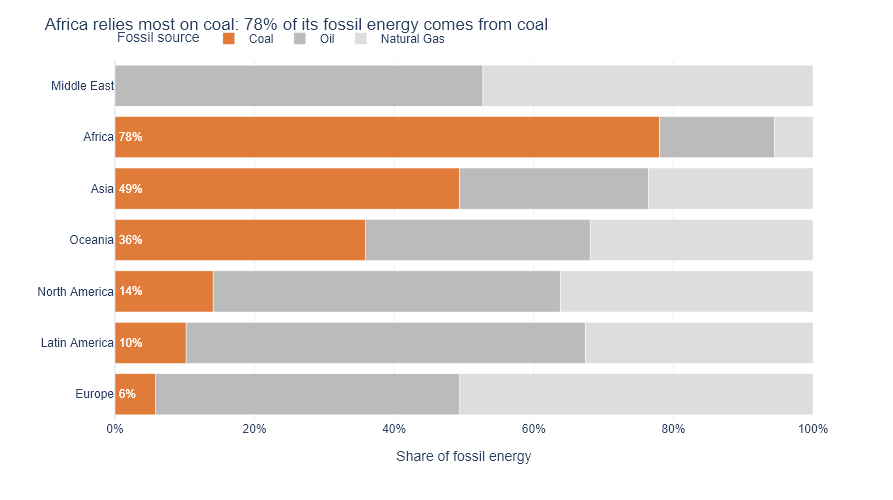

In [8]:
# Task 3

# Add up fossil TWh per Region and Source (reuses df_fossil from Task 1)
mix = df_fossil.groupby(['Region', 'Source'])['TWh'].sum().reset_index()

# Turn TWh into each region's share of its fossil total
mix['Share'] = mix['TWh'] / mix.groupby('Region')['TWh'].transform('sum')

# Sort regions by coal share, highest at the top
coal = mix.loc[mix['Source'] == 'Coal'].sort_values('Share', ascending=False)
region_order = coal['Region'].tolist()

# Most coal-dependent region (for the title)
top_region = coal.iloc[0]['Region']
top_share = coal.iloc[0]['Share']

# Labels on coal segments only
mix['Label'] = np.where(mix['Source'] == 'Coal', mix['Share'].map('{:.0%}'.format), '')

# Coal keeps its Task 1 colour; Oil and Gas are grey
colors = {
    'Coal':        '#E07B39',   # orange, same as Task 1
    'Oil':         '#BBBBBB',   # mid grey
    'Natural Gas': '#DDDDDD',   # light grey
}

fig = px.bar(
    mix,
    x='Share', y='Region',
    color='Source',
    orientation='h',
    text='Label',
    color_discrete_map=colors,
    category_orders={'Region': region_order,
                     'Source': ['Coal', 'Oil', 'Natural Gas']},   # coal on the baseline
    labels={'Share': 'Share of fossil energy', 'Source': 'Fossil source'},
    height=500, width=1000,
    template='plotly_white'
)

fig.update_traces(textposition='inside', insidetextanchor='start',
                  textfont=dict(color='white', size=12))

fig.update_layout(
    title=f'{top_region} relies most on coal: {top_share:.0%} of its fossil energy comes from coal',
    xaxis=dict(tickformat='.0%', range=[0, 1]),
    yaxis_title='',
    legend=dict(orientation='h', x=0, y=1.1),
    font=dict(family='Arial', size=12)
)

fig.show()

### Task 3 — reflection

**Your Task 1 treemap and this stacked bar show the same fossil data. Name one question each chart answers that the other cannot.**

*YOUR ANSWER HERE*

it shows the mix and the ranking. It can answer “Which region gets the largest share of its fossil energy from coal?” All the coal segments start from the same baseline and the regions are sorted, so the shares are easy to compare. In the treemap the coal rectangles are scattered and sized by TWh rather than share, so you can’t read that ranking from it.